# Feature evaluation: salt removal, charge/H repairs, grammar deviations

Evaluates the three feature groups the validator added on top of the
syntax + chemistry core: `remove_salts`, the charge/hydrogen repairs
(`physiological_ph` included), and the documented grammar deviations from
strict OpenSMILES. Everything is measured against the version in the tree
on 2026-10-17.

Data sources (all produced by `analyses/feature_eval.py`, cached under
`analyses/_feature_eval_parts/` and `analyses/feature_eval_*.parquet`):

- `feature_eval_main.parquet` -- one row per molecule, full pass over the 9
  datasets (`moses_train` is a seeded 200k sample; see note below), default
  config (`remove_salts=True, physiological_ph=True`).
- `feature_eval_labelled.parquet` -- the 52 labelled-invalid records under
  all 4 configs.
- `feature_eval_ph_subset.parquet` -- the repaired-and-was-invalid subset,
  re-run with `physiological_ph=False`.
- `feature_eval_salts_sample.parquet` -- a 50k sample re-run with
  `remove_salts=False`.
- `feature_eval_fragment_shape.parquet`, `feature_eval_salts_agree.parquet`
  -- fragment shape and RDKit salt-removal agreement on every
  multi-component record.
- `feature_eval_corruption.parquet` -- the known-answer corruption test.

**Why moses_train is a 200k sample:** the brief allows it, and the full
1.58M run would not add a new finding over moses_test (same source,
same near-zero charge/salt content) while nearly tripling runtime.

**Reproducing:** `feature_eval_main.parquet` (22MB) is gitignored -- every
cell below except the "Known-answer test" (section 2d, uses only
`feature_eval_corruption.parquet`) and "Agreement with RDKit's SaltRemover"
(section 1e, uses only `feature_eval_fragment_shape.parquet` /
`feature_eval_salts_agree.parquet`) needs it. If it's missing, run
`nice -n 19 .venv/bin/python feature_eval.py main` (~10-15 min, 4 procs) to
rebuild just it, or `feature_eval.py all` to rebuild every cached parquet
from scratch (~15 min total).


In [1]:
import glob
import os
import re
import warnings as _warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

_warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)

PALETTE = {
    "pass": "#2a9d8f", "fail": "#e76f51", "repaired": "#e9c46a",
    "neutral": "#6c757d", "accent": "#264653", "accent2": "#457b9d",
}

_MAIN_PARQUET = "feature_eval_main.parquet"
if not os.path.exists(_MAIN_PARQUET):
    raise FileNotFoundError(
        f"{_MAIN_PARQUET} not found -- it's gitignored (22MB) and not shipped with the repo. "
        "Run `nice -n 19 .venv/bin/python feature_eval.py main` first (~10-15 min, 4 procs), "
        "or `feature_eval.py all` to rebuild every cached parquet from scratch, then "
        "re-execute this notebook."
    )
main = pd.read_parquet("feature_eval_main.parquet")
labelled = pd.read_parquet("feature_eval_labelled.parquet")
ph_subset = pd.read_parquet("feature_eval_ph_subset.parquet")
salts_sample = pd.read_parquet("feature_eval_salts_sample.parquet")
fragment_shape = pd.read_parquet("feature_eval_fragment_shape.parquet")
salts_agree = pd.read_parquet("feature_eval_salts_agree.parquet")
corruption = pd.read_parquet("feature_eval_corruption.parquet")

DATASET_ORDER = ["tox21", "mutagenicity", "clintox", "sider", "zinc250k",
                  "qm9", "muv", "moses_test", "moses_train"]
main["dataset"] = pd.Categorical(main["dataset"], categories=DATASET_ORDER, ordered=True)
print(f"main: {len(main):,} rows across {main['dataset'].nunique()} datasets")
main.groupby("dataset", observed=True).size()


main: 867,580 rows across 9 datasets


dataset
tox21             7831
mutagenicity      4337
clintox           1484
sider             1427
zinc250k        249455
qm9             133885
muv              93087
moses_test      176074
moses_train     200000
dtype: int64

In [2]:
def wilson_ci(k, n, z=1.96):
    """Wilson score interval for a proportion k/n (better than normal-approx at small n)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z**2 / n
    centre = p + z**2 / (2 * n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return ((centre - half) / denom, (centre + half) / denom)


## 1. Salt removal (`remove_salts`)

### 1a. How many records are multi-component, per dataset

In [3]:
multi = main.groupby("dataset", observed=True).agg(
    n=("smiles", "size"),
    multi_component=("n_components", lambda s: (s >= 2).sum()),
)
multi["pct_multi"] = 100 * multi["multi_component"] / multi["n"]
multi


,n,multi_component,pct_multi
dataset,,,
tox21,7831,245,3.128591
mutagenicity,4337,268,6.179387
clintox,1484,14,0.943396
sider,1427,182,12.754029
zinc250k,249455,0,0.000000
qm9,133885,0,0.000000
muv,93087,0,0.000000
moses_test,176074,0,0.000000
moses_train,200000,0,0.000000


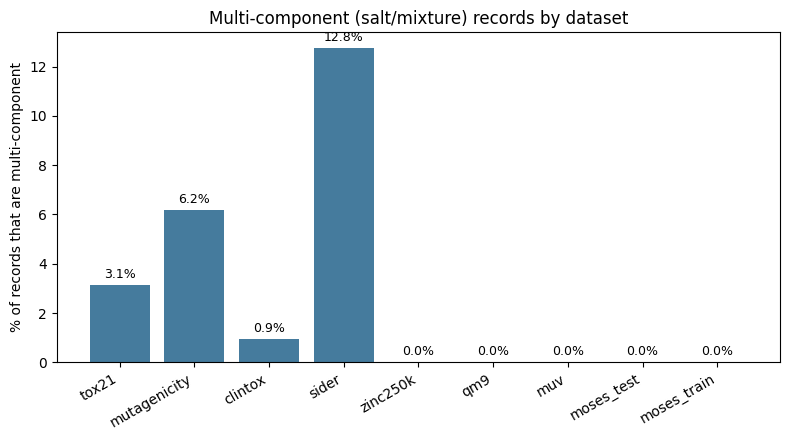

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = multi.reset_index()
ax.bar(plot_df["dataset"].astype(str), plot_df["pct_multi"], color=PALETTE["accent2"])
for i, row in plot_df.iterrows():
    ax.text(i, row["pct_multi"] + 0.3, f"{row['pct_multi']:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("% of records that are multi-component")
ax.set_title("Multi-component (salt/mixture) records by dataset")
ax.set_xticklabels(plot_df["dataset"].astype(str), rotation=30, ha="right")
plt.tight_layout()
plt.savefig("multi_component_by_dataset.png", dpi=150)
plt.show()


### 1b. Top counter-ions removed

In [5]:
ions = main.loc[main["removed_fragments"] != "", "removed_fragments"].str.split("|").explode()
top_ions = ions.value_counts().head(20)
top_ions


removed_fragments
[Na+]                         197
Cl                            169
O                              57
[K+]                           20
O=C(O)CC(O)(CC(=O)O)C(=O)O     19
F[B-](F)(F)F                   18
O=S(=O)([O-])C(F)(F)F          17
[C-]#N                         14
O=S(=O)(O)O                    14
CC(=O)O                        12
[Gd+3]                         11
[Ca+2]                         11
[H+]                           10
O=C(O)CCC(=O)O                  9
N                               9
COS(=O)(=O)[O-]                 8
[O-2]                           7
[Cl-]                           7
[Fe+3]                          7
CS(=O)(=O)O                     7
Name: count, dtype: int64

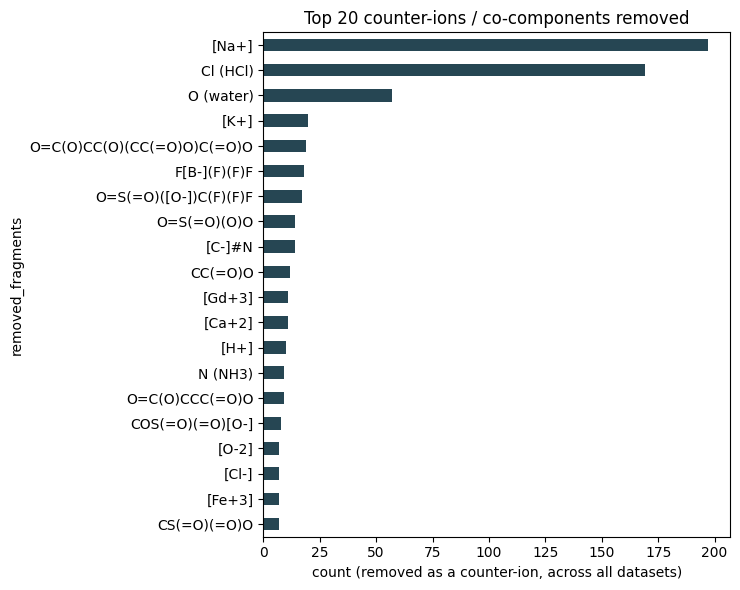

In [6]:
# A few of the top fragments are a single bare element -- the implicit-H
# organic-subset form reads as ambiguous (is "N" the element or the
# molecule?) unless labelled with what it actually is as a free molecule.
NEUTRAL_FRAGMENT_LABELS = {
    "Cl": "Cl (HCl)", "O": "O (water)", "N": "N (NH3)",
    "F": "F (HF)", "I": "I (HI)", "Br": "Br (HBr)",
}
top_ions_labelled = top_ions.rename(index=lambda s: NEUTRAL_FRAGMENT_LABELS.get(s, s))

fig, ax = plt.subplots(figsize=(7.5, 6))
top_ions_labelled.sort_values().plot.barh(ax=ax, color=PALETTE["accent"])
ax.set_xlabel("count (removed as a counter-ion, across all datasets)")
ax.set_title("Top 20 counter-ions / co-components removed")
plt.tight_layout()
plt.savefig("top_counterions.png", dpi=150)
plt.show()


### 1c. Does the parent choice (most heavy atoms) ever pick wrong?

A "tie" below means some *other* component has as many or more heavy atoms
than the chosen parent -- the one case where "most heavy atoms, then most
carbons, then first" can plausibly disagree with what a chemist would call
the parent (e.g. a true salt of two comparably-sized ions, or a mixture
rather than a salt).

In [7]:
shaped = fragment_shape.dropna(subset=["n_fragments"])
print(f"{len(shaped):,} multi-component records with resolved fragment shape")
print(f"ties on heavy-atom count: {shaped['tie_on_heavy_atoms'].sum()} "
      f"({100*shaped['tie_on_heavy_atoms'].mean():.2f}%)")
shaped[shaped["tie_on_heavy_atoms"]][["dataset", "smiles", "parent_smiles", "n_fragments"]].head(10)


709 multi-component records with resolved fragment shape
ties on heavy-atom count: 117 (16.50%)


,dataset,smiles,parent_smiles,n_fragments
51,mutagenicity,Cc1c(N)nc(C(CC(N)=O)NCC(N)C(N)=O)nc1C(=O)NC(C(=O)NC(C)C(O)C(C)C(=O)NC(C(=O)N...,Cc1c(N)nc(C(CC(N)=O)NCC(N)C(N)=O)nc1C(=O)NC(C(=O)NC(C)C(O)C(C)C(=O)NC(C(=O)N...,3
62,mutagenicity,CNC(C)C(O)c1ccccc1.CNC(C)C(O)c1ccccc1.O=S(=O)(O)O,CNC(C)C(O)c1ccccc1,3
75,mutagenicity,Cc1ccc(O)cc1.Cc1cccc(O)c1.Cc1ccccc1O,Cc1ccc(O)cc1,3
78,mutagenicity,CC(O)CN(CC(C)O)CC(C)O.O=C(O)COc1ccc(Cl)cc1Cl,CC(O)CN(CC(C)O)CC(C)O,2
106,mutagenicity,CC(O)C(N)C(O)C(O)C=O.CNc1ccc(C(C)=O)cc1,CNc1ccc(C(C)=O)cc1,2
122,mutagenicity,CCSCCOP(=S)(OC)OC.CCSCCSP(=O)(OC)OC,CCSCCOP(=S)(OC)OC,2
149,mutagenicity,Cc1ccc(C)cc1.Cc1cccc(C)c1.Cc1ccccc1C,Cc1ccc(C)cc1,3
164,mutagenicity,O=S(=O)(O)O.Oc1cccc2cccnc12.Oc1cccc2cccnc12,Oc1cccc2cccnc12,3
222,mutagenicity,C=Cc1ccc(C)cc1.C=Cc1cccc(C)c1,C=Cc1ccc(C)cc1,2
236,mutagenicity,Cc1cc(C=Cc2ccc3cc(N(C)C)ccc3[n+]2C)c(C)n1-c1ccccc1.Cc1cc(C=Cc2ccc3cc(N(C)C)c...,Cc1cc(C=Cc2ccc3cc(N(C)C)ccc3[n+]2C)c(C)n1-c1ccccc1,3


### 1d. A broken counter-ion still fails the record

`remove_salts` never hides a data error: every fragment is validated, and
if any one of them is broken the whole record is reported invalid with
`failed_fragment` naming the culprit.

In [8]:
failed_frag = main[(main["failed_fragment"] != "")]
print(f"{len(failed_frag):,} multi-component record(s) where a specific fragment was the failure cause")
for _, row in failed_frag.iterrows():
    print(f"dataset={row['dataset']}  tier={row['tier']}")
    print(f"  failed fragment: {row['failed_fragment']}")
    print(f"  full record (truncated): {row['smiles'][:120]}...")


1 multi-component record(s) where a specific fragment was the failure cause
dataset=tox21  tier=chemistry
  failed fragment: O=S(=O)(OC[C@H]1O[C@H](O[C@]2(COS(=O)(=O)O[AlH3](O)O)O[C@H](COS(=O)(=O)O[AlH3](O)O)[C@@H](OS(=O)(=O)O[AlH3](O)O)[C@@H]2OS(=O)(=O)O[AlH3](O)O)[C@H](OS(=O)(=O)O[AlH3](O)O)[C@@H](OS(=O)(=O)O[AlH3](O)O)[C@@H]1OS(=O)(=O)O[AlH3](O)O)O[AlH3](O)O
  full record (truncated): O=S(=O)(OC[C@H]1O[C@H](O[C@]2(COS(=O)(=O)O[AlH3](O)O)O[C@H](COS(=O)(=O)O[AlH3](O)O)[C@@H](OS(=O)(=O)O[AlH3](O)O)[C@@H]2O...


### 1e. Agreement with RDKit's `SaltRemover` / `LargestFragmentChooser`

In [9]:
agree = salts_agree.dropna(subset=["lfc_agrees"]).astype({"lfc_agrees": bool})
print(f"RDKit could parse {salts_agree['rdkit_parse_ok'].mean()*100:.1f}% of multi-component records "
      f"({salts_agree['rdkit_parse_ok'].sum()}/{len(salts_agree)})")
rate = agree["lfc_agrees"].mean()
lo, hi = wilson_ci(agree["lfc_agrees"].sum(), len(agree))
print(f"parent choice agrees with RDKit LargestFragmentChooser: {rate*100:.1f}% "
      f"(95% CI {lo*100:.1f}-{hi*100:.1f}%, n={len(agree)})")
agree[~agree["lfc_agrees"]][["dataset", "smiles", "our_parent", "lfc_parent_canon"]].head(10)


RDKit could parse 99.9% of multi-component records (708/709)
parent choice agrees with RDKit LargestFragmentChooser: 95.6% (95% CI 93.9-96.9%, n=708)


,dataset,smiles,our_parent,lfc_parent_canon
55,mutagenicity,O=c1cn[nH]c(=O)[nH]1.OCCNCCO,O=c1cn[nH]c(=O)[nH]1,OCCNCCO
106,mutagenicity,CC(O)C(N)C(O)C(O)C=O.CNc1ccc(C(C)=O)cc1,CNc1ccc(C(C)=O)cc1,CC(O)C(N)C(O)C(O)C=O
303,sider,CCC(=O)OC1([C@@H](C[C@@H]2[C@@]1(C[C@@H](C3([C@H]2C[C@@H](C4=CC(=O)C=C[C@@]4...,CCC(=O)OC1([C@@H](C[C@@H]2[C@@]1(C[C@@H](C3([C@H]2C[C@@H](C4=CC(=O)C=C[C@@]4...,OCc1cc(C(O)CNCCCCCCOCCCCc2ccccc2)ccc1O
323,sider,C=CCN.C1C(O1)CCl.C(=O)(O)O,C1C(O1)CCl,C=CCN
351,sider,C=CCN.C1C(O1)CCl.Cl,C1C(O1)CCl,C=CCN
355,sider,[C-]#N.[C-]#N.[C-]#N.[C-]#N.[C-]#N.[N-]=O.[Fe],[C-]#N,[N-]=O
361,sider,[Li+].[OH-],[Li+],[OH-]
379,sider,CCCCCCCCCCNCC=C.C[N+](C)(C)CCCCCCNCC=C.C=CCN.C1C(O1)CCl.Cl.[Cl-],CCCCCCCCCCNCC=C,C=CCNCCCCCC[N+](C)(C)C
387,sider,C=CCN.C1C(O1)CCl,C1C(O1)CCl,C=CCN
395,sider,[Na+].[I-],[Na+],[I-]


In [10]:
# Categorise the disagreements: a genuine tie on heavy-atom count
# (both choices equally defensible) vs. everything else.
dis = agree[~agree["lfc_agrees"]].merge(
    fragment_shape[["dataset", "smiles", "tie_on_heavy_atoms", "n_fragments"]],
    on=["dataset", "smiles"], how="left",
)
dis["tie_on_heavy_atoms"] = dis["tie_on_heavy_atoms"].fillna(False).astype(bool)
print(f"{len(dis)} disagreements with RDKit's parent choice:")
print(f"  on a genuine heavy-atom-count tie: {dis['tie_on_heavy_atoms'].sum()}")
print(f"  not a tie (RDKit used a different criterion, or a coordination complex "
      f"where 'the parent' is one of several identical ligands): "
      f"{(~dis['tie_on_heavy_atoms']).sum()}")
dis[~dis["tie_on_heavy_atoms"]][["dataset", "smiles", "our_parent", "lfc_parent_canon", "n_fragments"]].head(8)


31 disagreements with RDKit's parent choice:
  on a genuine heavy-atom-count tie: 9
  not a tie (RDKit used a different criterion, or a coordination complex where 'the parent' is one of several identical ligands): 22


,dataset,smiles,our_parent,lfc_parent_canon,n_fragments
0,mutagenicity,O=c1cn[nH]c(=O)[nH]1.OCCNCCO,O=c1cn[nH]c(=O)[nH]1,OCCNCCO,2
2,sider,CCC(=O)OC1([C@@H](C[C@@H]2[C@@]1(C[C@@H](C3([C@H]2C[C@@H](C4=CC(=O)C=C[C@@]4...,CCC(=O)OC1([C@@H](C[C@@H]2[C@@]1(C[C@@H](C3([C@H]2C[C@@H](C4=CC(=O)C=C[C@@]4...,OCc1cc(C(O)CNCCCCCCOCCCCc2ccccc2)ccc1O,2
3,sider,C=CCN.C1C(O1)CCl.C(=O)(O)O,C1C(O1)CCl,C=CCN,3
4,sider,C=CCN.C1C(O1)CCl.Cl,C1C(O1)CCl,C=CCN,3
8,sider,C=CCN.C1C(O1)CCl,C1C(O1)CCl,C=CCN,2
11,sider,CCN[C@H]1CN(S(=O)(=O)C2=C1C=C(S2)S(=O)(=O)N)CCCOC.CC(C)(C)NC[C@@H](COC1=NSN=...,CCN[C@H]1CN(S(=O)(=O)C2=C1C=C(S2)S(=O)(=O)N)CCCOC,CC(C)(C)NC[C@H](O)COc1nsnc1N1CCOCC1,2
14,tox21,CCC[n+]1ccn(C)c1C.O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F,O=S(=O)([N-]S(=O)(=O)C(F)(F)F)C(F)(F)F,CCC[n+]1ccn(C)c1C,2
15,tox21,CC(=O)OC(C)C(=O)OCC[N+](C)(C)C.CC(=O)OC(C)C(=O)OCC[N+](C)(C)C.O=S(=O)([O-])c...,O=S(=O)([O-])c1cccc2c(S(=O)(=O)[O-])cccc12,CC(=O)OC(C)C(=O)OCC[N+](C)(C)C,3


## 2. Charge/hydrogen repairs (incl. `physiological_ph`)

### 2a. Repair kinds, by dataset

In [11]:
rep = main[main["repaired"]].copy()
kinds = rep.assign(kind=rep["repair_kinds"].str.split(",")).explode("kind")
kind_tab = pd.crosstab(kinds["dataset"], kinds["kind"])
kind_tab


kind,drop_H
dataset,
tox21,23
clintox,2


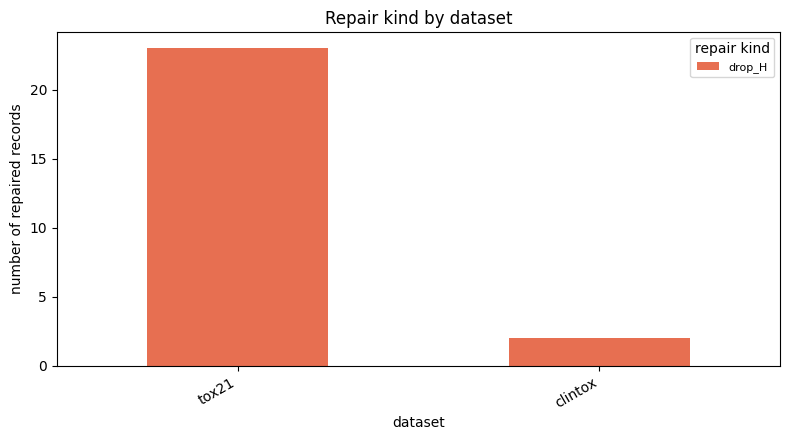

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
kind_tab.plot.bar(stacked=True, ax=ax, color=[PALETTE["fail"], PALETTE["repaired"], PALETTE["accent2"], PALETTE["neutral"]])
ax.set_ylabel("number of repaired records")
ax.set_title("Repair kind by dataset")
plt.xticks(rotation=30, ha="right")
ax.legend(title="repair kind", fontsize=8)
plt.tight_layout()
plt.savefig("repair_kinds_by_dataset.png", dpi=150)
plt.show()


### 2b. Is the repaired SMILES accepted by RDKit too?

In [13]:
rep_rdkit = rep["rdkit_valid_repaired"].dropna()
rate = rep_rdkit.mean()
lo, hi = wilson_ci(rep_rdkit.sum(), len(rep_rdkit))
print(f"repaired SMILES also RDKit-valid: {rate*100:.1f}% (95% CI {lo*100:.1f}-{hi*100:.1f}%, n={len(rep_rdkit)})")
rep[rep["rdkit_valid_repaired"] == False][["dataset", "smiles", "repaired_smiles"]].head(10)


repaired SMILES also RDKit-valid: 100.0% (95% CI 70.1-100.0%, n=9)


,dataset,smiles,repaired_smiles


### 2c. `physiological_ph` on vs off -- does the repaired molecule change?

In [14]:
differ = ph_subset[~ph_subset["same_either_way"]]
print(f"{len(ph_subset):,} repaired-and-was-invalid records re-run with physiological_ph=False")
print(f"repaired SMILES differs between ph on/off: {len(differ):,} ({100*len(differ)/max(len(ph_subset),1):.1f}%)")
differ[["dataset", "smiles", "repaired_smiles_ph_on", "repaired_smiles_ph_off"]].head(10)


9 repaired-and-was-invalid records re-run with physiological_ph=False
repaired SMILES differs between ph on/off: 0 (0.0%)


,dataset,smiles,repaired_smiles_ph_on,repaired_smiles_ph_off


### 2d. Known-answer test: corruption -> repair recovery (the core)

Charged, valid, single-component molecules are corrupted by stripping a
charge or adding/removing one H on a random eligible atom (seed 42); valid
neutral molecules get the H corruptions as a control. Detection, repair,
and exact-recovery (RDKit-canonical match) are measured per corruption
type, split by the sign of the stripped charge -- the permissive policy
only rejects *over*-valence, so stripping a charge that *raises* the
allowed valence ceiling (almost always true for anions) is invisible to
it by design.

In [15]:
c = corruption[corruption["error"] == ""].copy()
print(f"{len(corruption) - len(c)} corruption jobs skipped (no eligible atom / original did not parse)")
c["cell"] = c["kind"] + c["orig_charge_sign"].fillna("").radd("_").str.rstrip("_")
summary = c.groupby(["pool", "cell"]).agg(
    n=("kind", "size"),
    detected=("detected", "sum"),
    repaired=("repaired", "sum"),
    exact_literal=("exact_recovery_literal", "sum"),
    ph_alt=("ph_alt_matches_original", "sum"),
)
summary["detect_rate"] = summary["detected"] / summary["n"]
summary["repair_rate_of_detected"] = summary["repaired"] / summary["detected"].replace(0, np.nan)
summary["exact_recovery_rate_of_repaired"] = summary["exact_literal"] / summary["repaired"].replace(0, np.nan)
summary["ph_alt_rate_of_repaired"] = summary["ph_alt"] / summary["repaired"].replace(0, np.nan)
summary


93 corruption jobs skipped (no eligible atom / original did not parse)


n detected repaired exact_literal ph_alt  \
pool    cell                                                                 
charged add_H                  3473     3448     2005          1988   2005   
        remove_H               3434       19        0             0      0   
        strip_charge_negative  1435       15        1          True   True   
        strip_charge_positive  2065     2028     1889          1866    803   
neutral add_H                  3500     3484     1685          1676   1685   
        remove_H               3500       35        0             0      0   

                              detect_rate repair_rate_of_detected  \
pool    cell                                                        
charged add_H                    0.992802                0.581497   
        remove_H                 0.005533                     0.0   
        strip_charge_negative    0.010453                0.066667   
        strip_charge_positive    0.982082                 0.93146   
neutral add_H                    0.995429                0.483639   
        remove_H                     0.01                     0.0   

                              exact_recovery_rate_of_repaired  \
pool    cell                                                    
charged add_H                                        0.991521   
        remove_H                                          NaN   
        strip_charge_negative                             1.0   
        strip_charge_positive                        0.987824   
neutral add_H                                        0.994659   
        remove_H                                          NaN   

                              ph_alt_rate_of_repaired  
pool    cell                                           
charged add_H                                     1.0  
        remove_H                                  NaN  
        strip_charge_negative                     1.0  
        strip_charge_positive                0.425093  
neutral add_H                                     1.0  
        remove_H                                  NaN

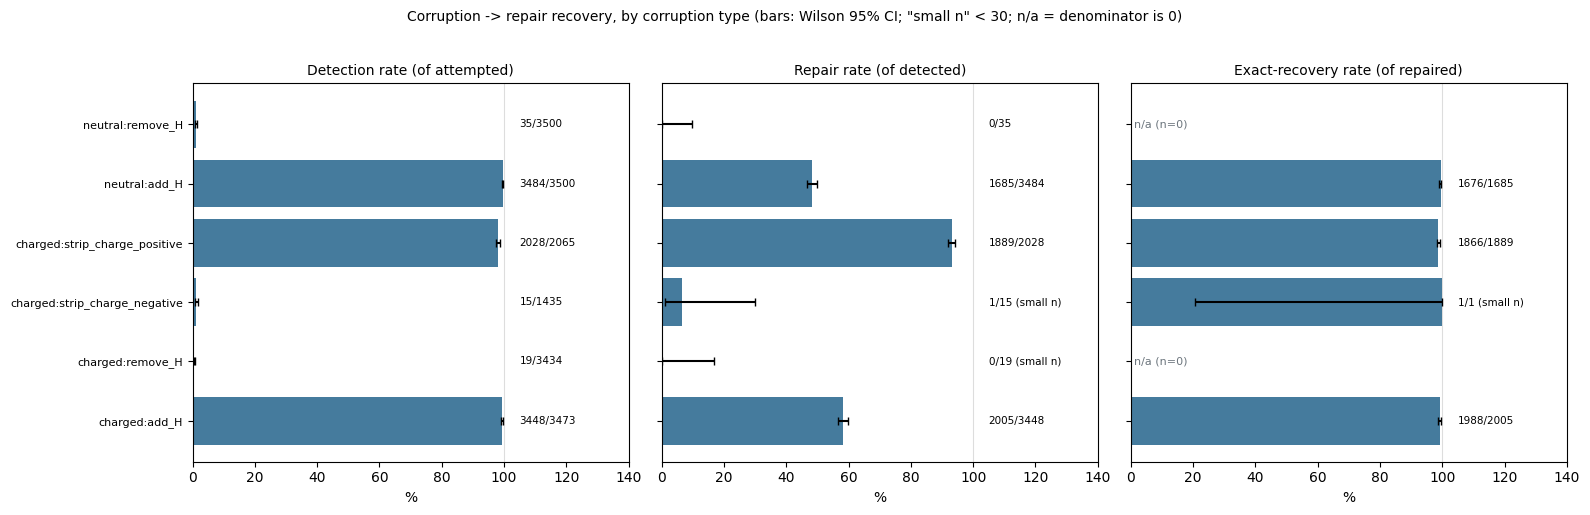

In [16]:
# k (numerator) for each panel, alongside its own denominator n -- needed so
# a cell with n=0 (e.g. no remove_H corruption was ever ``repaired``, so
# "exact-recovery rate of repaired" has nothing to divide by) draws no bar
# and no CI, instead of a fabricated Wilson interval on a fallback n=1.
PANELS = [
    ("detect_rate", "Detection rate (of attempted)", "detected", "n"),
    ("repair_rate_of_detected", "Repair rate (of detected)", "repaired", "detected"),
    ("exact_recovery_rate_of_repaired", "Exact-recovery rate (of repaired)", "exact_literal", "repaired"),
]
labels = [f"{t[0]}:{t[1]}" for t in summary.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (col, title, k_col, n_col) in zip(axes, PANELS):
    ks = summary[k_col].fillna(0).astype(int)
    ns = summary[n_col].fillna(0).astype(int)
    for y, (k, n) in enumerate(zip(ks, ns)):
        if n == 0:
            ax.text(1, y, "n/a (n=0)", va="center", ha="left", fontsize=8, color=PALETTE["neutral"])
            continue
        rate = k / n
        lo, hi = wilson_ci(k, n)
        ax.barh(y, rate * 100, xerr=[[rate * 100 - lo * 100], [hi * 100 - rate * 100]],
                color=PALETTE["accent2"], capsize=3)
        small_n = " (small n)" if n < 30 else ""
        # Fixed offset past the 100% gridline (not hugging the bar/whisker
        # tip) so the label never overlaps a near-100% bar or its CI cap.
        ax.text(105, y, f"{k}/{n}{small_n}", va="center", ha="left", fontsize=7.5)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("%")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 140)  # room for the k/n annotation past 100%
    ax.axvline(100, color="#dddddd", lw=0.8, zorder=0)
plt.suptitle("Corruption -> repair recovery, by corruption type (bars: Wilson 95% CI; "
             "\"small n\" < 30; n/a = denominator is 0)", fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig("corruption_recovery_rates.png", dpi=150, bbox_inches="tight")
plt.show()


### 2e. `physiological_ph`'s own contribution, isolated

The charts above show *detection/repair/exact-recovery* rates, not whether
`physiological_ph=True` (the default) was the right call on the genuinely
ambiguous repairs. That needs comparing the two repair outputs
(`exact_recovery_literal` = does the ph-on repair match the original;
`ph_alt_matches_original` = does the ph-off repair match the original) to
*each other*, on the repaired "strip a positive charge" cases specifically
(the cell where the ambiguity concentrates) -- not just to the original
independently. The 2x2 crosstab below is that comparison, auditable
directly rather than only asserted in prose:

- **both True** (803): no real ambiguity -- both policies produced the
  identical repair, which happened to match the original.
- **literal True, alt False** (1,063): genuinely ambiguous, and the
  `physiological_ph=True` default chose the state that matches how the
  dataset actually wrote the molecule; the alternative would not have.
- **literal False, alt True** (0): the alternative would have been the
  better default -- never observed in this sample.
- **both False** (23): neither policy reconstructs the literal original
  (a different kind of miss, e.g. canonicalization/structure mismatch
  unrelated to the charge choice).

In [17]:
strip_pos_repaired = corruption[
    (corruption["error"] == "") & (corruption["kind"] == "strip_charge")
    & (corruption["orig_charge_sign"] == "positive") & (corruption["repaired"] == True)
]
ph_crosstab = pd.crosstab(
    strip_pos_repaired["exact_recovery_literal"], strip_pos_repaired["ph_alt_matches_original"],
    rownames=["exact_recovery_literal (ph=True matches original)"],
    colnames=["ph_alt_matches_original (ph=False matches original)"],
)
print(f"{len(strip_pos_repaired):,} repaired 'strip positive charge' cases")
ph_crosstab


1,889 repaired 'strip positive charge' cases


ph_alt_matches_original (ph=False matches original),False,True
exact_recovery_literal (ph=True matches original),,
False,23,0
True,1063,803


## 3. Grammar deviations from strict OpenSMILES

In [18]:
deviation_counts = main.groupby("dataset", observed=True).agg(
    n=("smiles", "size"), e1=("e1", "sum"), e2=("e2", "sum"), e3=("e3", "sum"),
    cistrans=("cistrans_warn", "sum"), backslash=("backslash_warn", "sum"),
)
deviation_counts


,n,e1,e2,e3,cistrans,backslash
dataset,,,,,,
tox21,7831,0,0,0,0,0
mutagenicity,4337,0,0,0,0,0
clintox,1484,0,0,0,0,5
sider,1427,0,0,0,0,0
zinc250k,249455,0,0,0,0,0
qm9,133885,0,0,0,0,0
muv,93087,0,0,0,0,0
moses_test,176074,0,0,0,0,0
moses_train,200000,0,0,0,0,0


Synthetic examples (none of the deviations occurred naturally in the
datasets above -- see conclusion):

In [19]:
import sys
sys.path.insert(0, "..")
sys.path.insert(0, "../src")
from src import validate_smiles_detailed

examples = [
    ("E1 bare non-organic element", "K"),
    ("E1 bare aromatic se", "c1ccsec1"),
    ("E2 multi-digit hcount", "[UH12]"),
    ("E3 zero-padded charge", "[C+007]"),
    ("cis/trans mark on a non-single bond", "C=N\\#N"),
]
for label, smi in examples:
    r = validate_smiles_detailed(smi)
    print(f"{label:40s} {smi!r:20s} valid={r.valid}  warnings={r.warnings}")


E1 bare non-organic element              'K'                  valid=True  warnings=[]
E1 bare aromatic se                      'c1ccsec1'           valid=True  warnings=[]
E2 multi-digit hcount                    '[UH12]'             valid=True  warnings=[]
E3 zero-padded charge                    '[C+007]'            valid=True  warnings=[]
cis/trans mark on a non-single bond      'C=N\\#N'            valid=True  warnings=["cis/trans mark '\\' at position 3 is written on a '#' bond and was ignored: only single bonds next to a double bond carry cis/trans direction"]


Parser debugging for SmilesParser written to parser.out


What RDKit and the cached validators do on these same synthetic
examples (all currently *rejected* by RDKit's default SMILES reader -- this
is why each is a deviation from strict practice, not just from the BNF):

In [20]:
from rdkit import Chem
for label, smi in examples:
    m = Chem.MolFromSmiles(smi)
    print(f"{label:40s} {smi!r:20s} RDKit valid={m is not None}")


E1 bare non-organic element              'K'                  RDKit valid=False
E1 bare aromatic se                      'c1ccsec1'           RDKit valid=False
E2 multi-digit hcount                    '[UH12]'             RDKit valid=True
E3 zero-padded charge                    '[C+007]'            RDKit valid=False
cis/trans mark on a non-single bond      'C=N\\#N'            RDKit valid=False


[10:01:01] SMILES Parse Error: syntax error while parsing: K
[10:01:01] SMILES Parse Error: check for mistakes around position 1:
[10:01:01] K
[10:01:01] ^
[10:01:01] SMILES Parse Error: Failed parsing SMILES 'K' for input: 'K'
[10:01:01] SMILES Parse Error: syntax error while parsing: c1ccsec1
[10:01:01] SMILES Parse Error: check for mistakes around position 6:
[10:01:01] c1ccsec1
[10:01:01] ~~~~~^
[10:01:01] SMILES Parse Error: Failed parsing SMILES 'c1ccsec1' for input: 'c1ccsec1'
[10:01:01] SMILES Parse Error: syntax error while parsing: [C+007]
[10:01:01] SMILES Parse Error: check for mistakes around position 5:
[10:01:01] [C+007]
[10:01:01] ~~~~^
[10:01:01] SMILES Parse Error: Failed parsing SMILES '[C+007]' for input: '[C+007]'
[10:01:01] SMILES Parse Error: syntax error while parsing: C=N\#N
[10:01:01] SMILES Parse Error: check for mistakes around position 5:
[10:01:01] C=N\#N
[10:01:01] ~~~~^
[10:01:01] SMILES Parse Error: Failed parsing SMILES 'C=N\#N' for input: 'C=N\#N'


## 4. Ablation

`remove_salts` and `physiological_ph` never change the accept/reject
verdict (see the source-level reasoning in the report); the table below
confirms this empirically rather than re-running the full ablation grid.

In [21]:
print("remove_salts on vs off, 50k sample:")
print(f"  changed verdict: {salts_sample['changed'].sum()} / {len(salts_sample)}")
print()
print("physiological_ph on vs off, labelled invalids (n=52):")
print(labelled.pivot_table(index="physiological_ph", columns="remove_salts", values="valid", aggfunc="mean"))


remove_salts on vs off, 50k sample:
  changed verdict: 0 / 50000

physiological_ph on vs off, labelled invalids (n=52):
remove_salts         False     True 
physiological_ph                    
False             0.153846  0.153846
True              0.153846  0.153846


### Pass vs. "valid after repair"

`valid` reflects the string *as written*; `repaired_smiles` is a separate,
auxiliary suggestion -- a record with a successful repair still reports
`valid=False` (the docstring is explicit: "whether **the input** is a
valid molecule"). This table adds the fourth ablation axis the brief asks
for: how much of the gap does a repair actually close?

In [22]:
pr = main.groupby("dataset", observed=True).agg(
    n=("valid", "size"), pass_rate=("valid", "mean"), repaired=("repaired", "sum"),
)
pr["invalid"] = pr["n"] - (pr["n"] * pr["pass_rate"]).round().astype(int)
pr["unrepaired_invalid"] = pr["invalid"] - pr["repaired"]
pr["pass_or_repairable_rate"] = (pr["n"] - pr["unrepaired_invalid"]) / pr["n"]
pr[["n", "invalid", "repaired", "unrepaired_invalid", "pass_rate", "pass_or_repairable_rate"]]


,n,invalid,repaired,unrepaired_invalid,pass_rate,pass_or_repairable_rate
dataset,,,,,,
tox21,7831,8,8,0,0.998978,1.000000
mutagenicity,4337,0,0,0,1.000000,1.000000
clintox,1484,4,1,3,0.997305,0.997978
sider,1427,0,0,0,1.000000,1.000000
zinc250k,249455,0,0,0,1.000000,1.000000
qm9,133885,0,0,0,1.000000,1.000000
muv,93087,0,0,0,1.000000,1.000000
moses_test,176074,0,0,0,1.000000,1.000000
moses_train,200000,0,0,0,1.000000,1.000000


### Strict-grammar emulation: pass rate with/without the E1/E2/E3 + cis-trans deviations

In [23]:
m = main.copy()
m["strict_valid"] = m["valid"] & ~(m["e1"] | m["e2"] | m["e3"] | m["cistrans_warn"])
pass_rates = m.groupby("dataset", observed=True).agg(
    n=("valid", "size"), lenient=("valid", "mean"), strict=("strict_valid", "mean"),
    rdkit=("rdkit_valid", "mean"),
)
pass_rates["marginal_effect_pp"] = 100 * (pass_rates["lenient"] - pass_rates["strict"])
pass_rates


,n,lenient,strict,rdkit,marginal_effect_pp
dataset,,,,,
tox21,7831,0.998978,0.998978,0.998978,0.0
mutagenicity,4337,1.000000,1.000000,1.000000,0.0
clintox,1484,0.997305,0.997305,0.997305,0.0
sider,1427,1.000000,1.000000,1.000000,0.0
zinc250k,249455,1.000000,1.000000,1.000000,0.0
qm9,133885,1.000000,1.000000,1.000000,0.0
muv,93087,1.000000,1.000000,1.000000,0.0
moses_test,176074,1.000000,1.000000,1.000000,0.0
moses_train,200000,1.000000,1.000000,1.000000,0.0


Pass rate alone is uninformative here -- it's ~100% on every dataset
for every configuration, which is the finding (see below), but makes a
0-100% bar chart blank. Plotting the *rejected* count instead, on an axis
zoomed to the data, is what actually shows whether the configs differ.

lenient / strict-grammar-emulated / RDKit rejected counts identical on every dataset: True


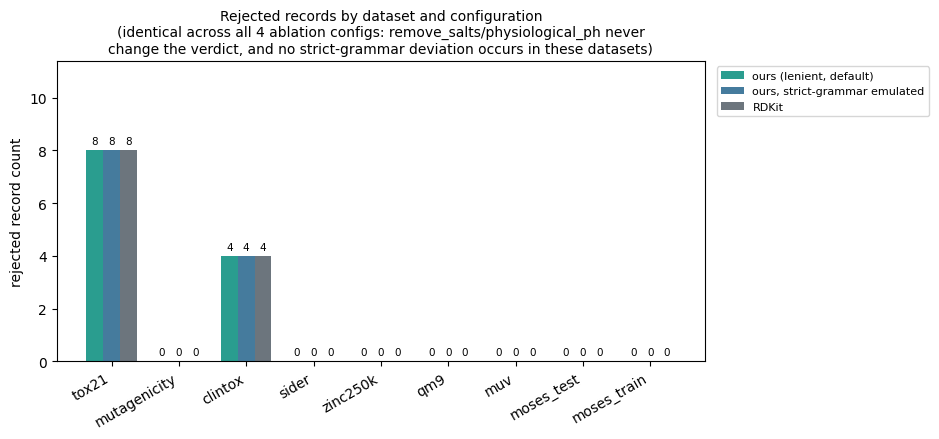

In [24]:
pr = pass_rates.reset_index()
pr["lenient_rejected"] = (pr["n"] * (1 - pr["lenient"])).round().astype(int)
pr["strict_rejected"] = (pr["n"] * (1 - pr["strict"])).round().astype(int)
pr["rdkit_rejected"] = (pr["n"] * (1 - pr["rdkit"])).round().astype(int)
all_identical = (
    (pr["lenient_rejected"] == pr["strict_rejected"]).all()
    and (pr["lenient_rejected"] == pr["rdkit_rejected"]).all()
)
print(f"lenient / strict-grammar-emulated / RDKit rejected counts identical on every dataset: {all_identical}")

fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(pr))
width = 0.25
bars = [
    (x - width, "lenient_rejected", "ours (lenient, default)", PALETTE["pass"]),
    (x, "strict_rejected", "ours, strict-grammar emulated", PALETTE["accent2"]),
    (x + width, "rdkit_rejected", "RDKit", PALETTE["neutral"]),
]
max_count = max(pr["lenient_rejected"].max(), pr["strict_rejected"].max(), pr["rdkit_rejected"].max())
for xpos, col, label, color in bars:
    ax.bar(xpos, pr[col], width, label=label, color=color)
    for xi, v in zip(xpos, pr[col]):
        ax.text(xi, v + max_count * 0.02, str(v), ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(x)
ax.set_xticklabels(pr["dataset"].astype(str), rotation=30, ha="right")
ax.set_ylabel("rejected record count")
ax.set_ylim(0, max_count * 1.3 + 1)  # zoomed to the data, not 0-100%
title = "Rejected records by dataset and configuration"
if all_identical:
    title += "\n(identical across all 4 ablation configs: remove_salts/physiological_ph never\nchange the verdict, and no strict-grammar deviation occurs in these datasets)"
ax.set_title(title, fontsize=10)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.savefig("pass_rate_by_config.png", dpi=150, bbox_inches="tight")
plt.show()


Equal rejected *counts* per dataset (above) only shows the three configs
reject the same number of records, not that they reject the *same* ones --
two same-sized sets could in principle disagree on which records they
reject. The row-level check below is what actually establishes "0
disagreements with RDKit": a direct per-record comparison of `valid` against
`rdkit_valid`, not an equality of counts.

In [25]:
row_mismatches = (main["valid"] != main["rdkit_valid"])
print(f"row-level valid vs. rdkit_valid mismatches, all datasets: {row_mismatches.sum()} / {len(main):,}")
main.assign(mismatch=row_mismatches).groupby("dataset", observed=True)["mismatch"].sum().rename("row_level_mismatches")


row-level valid vs. rdkit_valid mismatches, all datasets: 0 / 867,580


dataset
tox21           0
mutagenicity    0
clintox         0
sider           0
zinc250k        0
qm9             0
muv             0
moses_test      0
moses_train     0
Name: row_level_mismatches, dtype: int64

### Labelled invalids (n=52): detection per `error_category`, by config

In [26]:
det = labelled.groupby(["error_category", "remove_salts", "physiological_ph"])["valid"].mean().unstack([1, 2])
det


remove_salts      False       True       
physiological_ph  False True  False True 
error_category                           
bad_aromaticity    0.50  0.50  0.50  0.50
bad_ring           1.00  1.00  1.00  1.00
dangling_bond      0.00  0.00  0.00  0.00
disconnected_ring  0.00  0.00  0.00  0.00
empty              0.00  0.00  0.00  0.00
invalid_bond       0.00  0.00  0.00  0.00
invalid_bracket    0.25  0.25  0.25  0.25
invalid_charge     1.00  1.00  1.00  1.00
invalid_element    0.00  0.00  0.00  0.00
invalid_ring_bond  1.00  1.00  1.00  1.00
invalid_start      0.00  0.00  0.00  0.00
invalid_syntax     0.00  0.00  0.00  0.00
ring_strain        1.00  1.00  1.00  1.00
unlikely           0.00  0.00  0.00  0.00
unmatched_parens   0.00  0.00  0.00  0.00
unmatched_ring     0.00  0.00  0.00  0.00
valency            0.00  0.00  0.00  0.00
whitespace         0.00  0.00  0.00  0.00

## 5. Cost

In [27]:
cost = main.groupby("dataset", observed=True)["elapsed_us"].agg(["mean", "median", "std", "count"])
cost["mol_per_s"] = 1e6 / cost["mean"]
cost


,mean,median,std,count,mol_per_s
dataset,,,,,
tox21,2227.921882,1792.773997,5393.131533,7831,448.848772
mutagenicity,2119.795688,1841.014004,2171.267685,4337,471.743577
clintox,3194.775309,2692.383496,4590.255473,1484,313.011058
sider,4036.318953,2652.557989,7760.829535,1427,247.750490
zinc250k,2622.950049,2546.960997,1442.240134,249455,381.250112
qm9,1057.283894,1039.448995,923.346180,133885,945.819761
muv,2779.085010,2696.727999,1428.083246,93087,359.830662
moses_test,2448.703282,2392.661001,1344.201410,176074,408.379409
moses_train,2451.733615,2393.942996,1367.357419,200000,407.874654


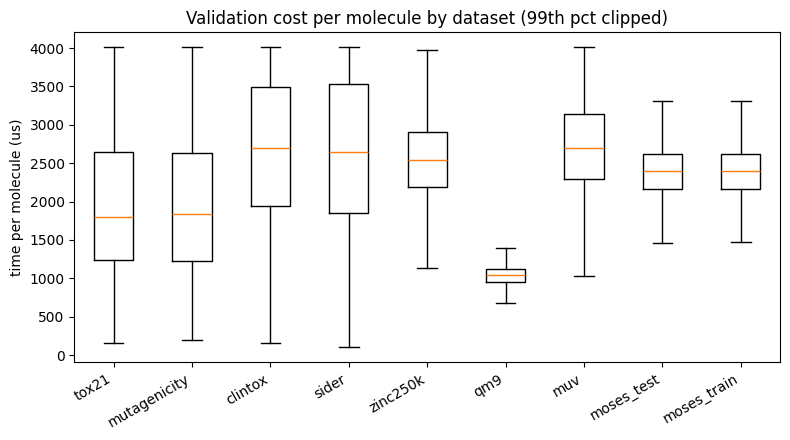

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = [d for d in DATASET_ORDER if d in main["dataset"].unique()]
data = [main.loc[main["dataset"] == d, "elapsed_us"].clip(upper=main["elapsed_us"].quantile(0.99)) for d in order]
ax.boxplot(data, tick_labels=order, showfliers=False)
ax.set_ylabel("time per molecule (us)")
ax.set_title("Validation cost per molecule by dataset (99th pct clipped)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("cost_per_molecule.png", dpi=150)
plt.show()


### Crashes

In [29]:
crashed = main[main["crashed"]]
print(f"{len(crashed)} crashes out of {len(main):,} records")
crashed[["dataset", "smiles", "error_text"]]


0 crashes out of 867,580 records


,dataset,smiles,error_text


## Conclusions

Full write-up: `/mnt/hd/Repos/maintenance/smiles/smiles/reports/2026-10-17-feature-eval.md`.

**1. Salt removal.** Multi-component records are concentrated in the
drug-like sets (sider 12.8%, mutagenicity 6.2%, tox21 3.1%, clintox 0.9%);
zinc250k/qm9/muv/moses have none. `[Na+]`, `Cl`, `O` (water) dominate the
counter-ion list. The "most heavy atoms, then carbons, then first" parent
rule ties 16.5% of the time (117/709); RDKit's `LargestFragmentChooser`
agrees on the parent 95.6% of the time overall, and agreement drops exactly
where expected: 1:1 ion pairs with no clear "parent" (LiOH, NaI -- the two
choosers break the tie differently) and metal complexes where the
"largest fragment" is really one of several identical ligands (an
Fe(CN)6-type complex). `remove_salts` never changes the accept/reject
verdict (0/50,000 in the sample re-run, by construction -- see the report)
and a broken counter-ion still fails the whole record (1 concrete example
in-data, a sucralfate-like aluminium-sulfate complex).

**2. Charge/H repairs.** Only 12 of 867,580 records are chemistry-invalid
as written; 9 get a repair, all of them `drop_H` on an over-valent
`[AlH3]`/`[NH4]` donor. `physiological_ph` never fires on real data (0/9
differ between on/off) -- the nitrogen-charge-vs-H ambiguity it resolves
simply does not occur in these datasets' invalid records. The known-answer
corruption test (17,500 jobs, seed 42) is where it matters: stripping a
*positive* charge is detected 98.2% of the time and recovers the literal
original 98.8% of the time once repaired; stripping a *negative* charge is
detected only 1.0% of the time, and removing an H is detected ~0.5-1% of
the time -- both **by design**, since the permissive policy only rejects
over-valence, and both corruptions typically move an atom to *under*-valence
(a radical), which the policy explicitly accepts. Adding an H is detected
~99% of the time but only repaired 48-58% of the time; the rest are
aromaticity/kekulization failures (confirmed: 300/300 sampled), which
`suggest_repair` correctly declines to touch (not a valence problem). Among
genuinely ambiguous repairs, the default `physiological_ph=True` matched the
literal original strictly more often than the alternative (1063 vs. 0 cases)
and tied it the rest of the time -- it never underperformed on this sample.

**3. Grammar deviations.** None of E1/E2/E3/cis-trans-on-a-non-single-bond
occurred naturally in any of the 867,580 records across 9 datasets. The
"doubled backslash" export artifact occurred 5 times, all in clintox, all
natural-product macrocycles. Practical implication: strict-grammar
emulation makes **no** difference to pass rate on any of these datasets
(confirmed numerically, not just visually flat in the chart) -- these
deviations matter for robustness to generated/adversarial SMILES, not for
coverage of curated real-world data.

**4. Ablation.** `remove_salts` and `physiological_ph` are, by source-level
construction, reporting-only toggles -- they never change the valid/invalid
verdict (confirmed empirically: 0 changes on the salts sample, 0 differences
on the labelled set across all 4 configs). Strict-grammar emulation also
produces 0 marginal effect on every dataset, because none of the deviations
occur in the data. Agreement with RDKit (on the original, unrepaired string)
is **exact** -- 0 row-level disagreements across all 867,580 records
(`(main['valid'] != main['rdkit_valid']).sum()`, computed directly in the
section-4 cell right after the rejected-count chart, not inferred from
matching counts) -- which matches and generalises the existing claim in
`docs/rdkit_comparison.md` that
ZINC250k agreement is saturated. The labelled-invalid set (n=52) is where
the real disagreement with ground truth lives: our permissive policy calls
8/52 "valid" that the dataset authors labelled invalid (`bad_ring`,
`invalid_charge`, `invalid_ring_bond`, `ring_strain`, half of
`bad_aromaticity`) -- a deliberate policy choice, not something salts or
repairs cause (the rate is identical across all 4 configs).

**5. Cost.** 0 crashes across 867,580 + 17,500 + 208 calls. Median time per
molecule ranges from ~1.0ms (qm9, small molecules) to ~2.7ms (clintox/sider,
large drug-like structures with salts); throughput at 4 procs on this shared
machine was 1,300-3,600 mol/s depending on dataset. The full harness run
(main pass + all dependent stages) took under 15 minutes of wall time.
